# Figure 7: Model Fields

## Load Modules

In [1]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import matplotlib.ticker as mticker
from matplotlib import path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.patches import Polygon
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe

import xarray as xr
from netCDF4 import Dataset
from xgcm import Grid
import cmaps
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob

import rioxarray

from dask.diagnostics import ProgressBar

from scipy.ndimage import gaussian_filter1d

from pyproj import Transformer

import seawater as sw
import gsw

import calendar

import pickle

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/sitecustomize.py:72: UserWarning: The seawater library is deprecated! Please use gsw instead.
  mod = _real_import(name, globals, locals, fromlist, level)


## Define Resuable Functions

In [2]:
def inpolygon(xq, yq, xv, yv):
    shape = xq.shape
    xq = xq.reshape(-1)
    yq = yq.reshape(-1)
    xv = xv.reshape(-1)
    yv = yv.reshape(-1)
    q = [(xq[i], yq[i]) for i in range(xq.shape[0])]
    p = path.Path([(xv[i], yv[i]) for i in range(xv.shape[0])])
    return p.contains_points(q).reshape(shape)

def createMasks(ds):
    ds['mask_zice'] = (ds.mask_rho.where(ds.zice<0)==1) # make a logic mask for ice
    ds['mask_openocean'] = ds.mask_rho*(ds.mask_zice==0)
    ds['mask_openoceanNaN'] = ds.mask_openocean.where(ds.mask_openocean)
    ds['mask_rhoNaN'] = ds.mask_rho.where(ds.mask_rho)
    ds['mask_ziceNaN'] = ds.mask_zice.where(ds.mask_zice)

    poly_shelf = np.array([
        [1.55e6,600000],
        [2.25e6,600000],
        [2.25e6,800000],
        [2.20e6,830000],
        [1.55e6,890000]])
    
    mask_roi = inpolygon(ds.x_rho.values, ds.y_rho.values,poly_shelf[:,0], poly_shelf[:,1])
    ds['mask_zice_roi'] = ds.mask_zice*mask_roi
    roi_label1 = 'amery'
    ds.mask_zice_roi.attrs['long_name']=roi_label1

# Find the coordinates of the four corners of one cell provided
def cell_polygon(j, i, x_psi, y_psi):
    """Corner coords of rho cell (j,i) from its 4 surrounding psi points."""
    # Convert psi (corner) points to a NumPy array
    xp, yp = np.asarray(x_psi), np.asarray(y_psi)
    return [(xp[j-1, i-1], yp[j-1, i-1]),   # SW
            (xp[j-1, i  ], yp[j-1, i  ]),   # SE
            (xp[j,   i  ], yp[j,   i  ]),   # NE
            (xp[j,   i-1], yp[j,   i-1])]   # NW

def block_polygon(j, i, x_psi, y_psi, r=1):
    """Outer boundary of a (2r+1)x(2r+1) block of rho cells centred on (j,i)."""
    xp, yp = np.asarray(x_psi), np.asarray(y_psi)
    return [(xp[j-1-r, i-1-r], yp[j-1-r, i-1-r]),   # SW
            (xp[j-1-r, i+r  ], yp[j-1-r, i+r  ]),   # SE
            (xp[j+r,   i+r  ], yp[j+r,   i+r  ]),   # NE
            (xp[j+r,   i-1-r], yp[j+r,   i-1-r])]   # NW
    
def nearest_cell(lon0, lat0, lon_rho, lat_rho):
    lon  = np.deg2rad(np.asarray(lon_rho)); lat  = np.deg2rad(np.asarray(lat_rho))
    lon0r, lat0r = np.deg2rad(lon0), np.deg2rad(lat0)
    dlon, dlat = lon - lon0r, lat - lat0r
    a = np.sin(dlat/2)**2 + np.cos(lat0r)*np.cos(lat)*np.sin(dlon/2)**2
    dist = 2*np.arcsin(np.sqrt(a))                      # great-circle distance
    j, i = np.unravel_index(np.nanargmin(dist), dist.shape)   # flat argmin -> (eta, xi)
    return int(j), int(i)

def style_map(ds, ax, boreholes_amisor, wct_colour=None):
    """Apply the common map overlays and extent to a panel."""
    # ax.contour(ds.x_rho, ds.y_rho, ds.h*ds.mask_rho, levels=(0,250,500,750,1000,2000,3000), colors='grey', linewidths=1)
    ax.contour(ds.x_rho, ds.y_rho, ds.zice*ds.mask_rho, levels=(-1,0), colors='red', linestyles='--', linewidths=0.75)

    wct = (ds.h + ds.zice) * ds.mask_rho # zice is negative, so this is h - |zice|
    if wct_colour is not None:
        cw = ax.contour(ds.x_rho, ds.y_rho, wct, levels=np.arange(0, 3000, 200), colors=wct_colour, linewidths=0.5, zorder=6)
    # ax.clabel(cw, inline=True, fontsize=6, fmt='%.0f')
        
    # Zoomed out
    # ax.set_xlim(1.68e6, 2.45e6)
    # ax.set_ylim(0.52e6, 1.0e6)

    # Eastern flank zoomed in 
    # ax.set_xlim(1.975e6, 2.45e6)
    # ax.set_ylim(0.52e6, 0.75e6)

    # Just AIS
    ax.set_xlim(1.975e6, 2.25e6)
    ax.set_ylim(0.58e6, 0.84e6)

    # Set an equal aspect ratio so that the map doesn't get stretched
    ax.set_aspect('equal', adjustable='box')
    
    ax.xaxis.set_major_formatter(ticks_x)
    ax.yaxis.set_major_formatter(ticks_y)
    for name, info in boreholes_amisor.items():
        lon, lat = info['lonlat']
        bx, by = ll_to_xy.transform(lon, lat)                     # true site -> metres
        ax.plot(bx, by, '.', color='black', ms=10, zorder=8,
                path_effects=[pe.withStroke(linewidth=2, foreground='white')])
        # ax.annotate(name, xy=(bx, by), xytext=(6, 0), textcoords='offset points', color='blue', va='center', zorder=6, bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.4))
        if name in ("AM01", "AM04", "AM05"):
            dx, dy, ha, va = 6, 0, "left", "center"
        elif name == "AM02":
            dx, dy, ha, va = -6, 0, "right", "center"
        elif name == "AM03":
            dx, dy, ha, va = 0, 6, "center", "bottom"
        elif name == "AM06":
            dx, dy, ha, va = 0, -6, "center", "top"
        ax.annotate(name, xy=(bx, by), xytext=(dx, dy), textcoords='offset points', color='black', ha=ha, va=va, zorder=8,
                    path_effects=[pe.withStroke(linewidth=1.5, foreground='white')])

## Load Datasets

In [3]:
# ---------- GRID ----------
grd = xr.open_dataset('/g/data/jk72/deg581/apom/frc/amery_v2km_v13_grd.nc')

# ---------- MODEL OUTPUT ----------
ds_CTRL = xr.open_dataset('/g/data/gv90/ad6790/amery-amisor/data/proc/ctrl_climatology.nc', chunks={})
print(ds_CTRL.nbytes/1e9,'G')

# ---------- LIMA ----------
lima_full = rioxarray.open_rasterio('/g/data/jk72/deg581/apom/ana/data/raw/lima/00000-20080319-092059124.tif')
lima = lima_full.where((lima_full.x>1.68e6)&(lima_full.x<2.5e6)&(lima_full.y>.4e6)&(lima_full.y<1e6),drop=True)

# ---------- FORCING ----------
frc = xr.open_dataset('/g/data/jk72/deg581/apom/frc/amery_v2km_tamura+era_shflux.nc')
ds_his = xr.open_dataset('/g/data/jk72/deg581/apom/frc/amery_v2km_tamura+era_swflux.nc') 

40.109673352 G


## Handle Loaded Datasets

In [4]:
# ---------- GRID ----------
grd['hc']=ds_CTRL.hc
grd['s_w']=ds_CTRL.s_w
grd['s_rho']=ds_CTRL.s_rho
grd['Cs_w']=ds_CTRL.Cs_w
grd['Cs_r']=ds_CTRL.Cs_r

createMasks(grd)

# ---------- MODEL OUTPUT ----------
with ProgressBar():
    ds_CTRL = ds_CTRL.load()

[########################################] | 100% Completed | 528.41 s


## Find AMISOR Borehole Locations

In [5]:
# Initialise a dictionary to hold information on the physical boreholes and moorings
# Borehole lon/lats are at deployment (most change across recording period by less than ~2 km, and maximum ~5 km) 
# Index 0 is coordinates (lon, lat)
# Index 1 is a list of mooring depths in dbar (calculated from average pressure at deployment)
boreholes_amisor = {
    'AM01': {'lonlat': (71.417083, -69.442033), 'avg_pressures': [441.1, 581.6, 743.4], 'ice_draft': 422, 'ocean_floor': 783},
    'AM02': {'lonlat': (72.639983, -69.713767), 'avg_pressures': [338.5, 562.7, 770.2], 'ice_draft': 324, 'ocean_floor': 790},
    'AM03': {'lonlat': (70.332167, -70.561167), 'avg_pressures': [653.6, 861.5, 1211.1], 'ice_draft': 648, 'ocean_floor': 1265},
    'AM04': {'lonlat': (70.290333, -69.8995), 'avg_pressures': [550.4, 693.0, 814.7], 'ice_draft': 539, 'ocean_floor': 938},
    'AM05': {'lonlat': (69.675, -70.231667), 'avg_pressures': [580.5, 738.8, 876.6], 'ice_draft': 554, 'ocean_floor': 909},
    'AM06': {'lonlat': (71.363817, -70.236083), 'avg_pressures': [551.4, 680.8, 790.3], 'ice_draft': 533, 'ocean_floor': 827}
}

# Initialise a dictionary to hold information on the borehole locations represented by the model
boreholes_model = {}
    
# Find the nearest cells to each borehole location
# Iterate over each physical borehole
for name, info in boreholes_amisor.items():
    # Extract the actual lat/lon of the physical boreholes
    lon, lat = info['lonlat']
    # Create a new instance/key of the physical borehole in the model output
    boreholes_model[name] = {}
    # Map the actual lat/lon to the cell in the model which includes this lat/lon
    boreholes_model[name]['centre_cell'] = nearest_cell(lon, lat, ds_CTRL.lon_rho, ds_CTRL.lat_rho)
    j, i = boreholes_model[name]['centre_cell']
    # Initialise a list to hold the centre cell and the surrounding 8 cells
    boreholes_model[name]['nine_cells'] = []
    # Iterate over dj and di to calculate the coordinates of the cells surrounding the centre cell
    for dj in (-1, 0, 1):
        for di in (-1, 0, 1):
            boreholes_model[name]['nine_cells'].append((j + dj, i + di))

# Create a resuable transformation for converting (lon,lat) -> (x,y)
ll_to_xy = Transformer.from_crs("EPSG:4326", "EPSG:3031", always_xy=True) 

## Define Consistent Arguments for Plotting

In [6]:
# Keyword arguments for plotting temperature and salinity colourmaps from the model
# OR use cm.thermal
# temp_kwargs = dict(cmap='cmo.thermal', levels=np.arange(-2.3, -1.69, 0.05), extend='both')
# # OR use cm.haline
# salt_kwargs = dict(cmap='viridis', levels=np.arange(34.5, 34.81, 0.05), extend='both')

# OR use cm.thermal
temp_kwargs = dict(cmap='cmo.thermal', vmin=-2.3, vmax=-1.7, shading='gouraud', rasterized=True)
# OR use cm.haline
salt_kwargs = dict(cmap='viridis', vmin=34.5, vmax=34.8, shading='gouraud', rasterized=True)

melt_kwargs = dict(cmap='RdBu_r', norm=TwoSlopeNorm(vmin=-2, vcenter=0, vmax=10), shading='gouraud', rasterized=True)

plt.rcParams.update({
    'font.size': 12,          # base size, everything else scales from it
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
})

## Seasonal Plots: Sea-Ice Seasons

In [7]:
# late_summer_period
s1 = slice(20,80)
# early_seaice_period
s2 = slice(80,130)
# seaice_period
s3 = slice(130,330)
# early_summer_period1
s4_1 = slice(330,366)
# early_summer_period2
s4_2 = slice(0,20)

us_rho_s1   = ds_CTRL.u_rho_doy.sel(dayofyear=s1).mean(dim='dayofyear')   
vs_rho_s1   = ds_CTRL.v_rho_doy.sel(dayofyear=s1).mean(dim='dayofyear')   
us_rho_s2   = ds_CTRL.u_rho_doy.sel(dayofyear=s2).mean(dim='dayofyear')   
vs_rho_s2   = ds_CTRL.v_rho_doy.sel(dayofyear=s2).mean(dim='dayofyear')   
us_rho_s3   = ds_CTRL.u_rho_doy.sel(dayofyear=s3).mean(dim='dayofyear')   
vs_rho_s3   = ds_CTRL.v_rho_doy.sel(dayofyear=s3).mean(dim='dayofyear')   
us_rho_s4   = (xr.concat( [ds_CTRL.u_rho_doy.sel(dayofyear=s4_1),ds_CTRL.u_rho_doy.sel(dayofyear=s4_2)],dim='dayofyear')).mean(dim='dayofyear')
vs_rho_s4   = (xr.concat( [ds_CTRL.v_rho_doy.sel(dayofyear=s4_1),ds_CTRL.v_rho_doy.sel(dayofyear=s4_2)],dim='dayofyear')).mean(dim='dayofyear')

ubar_rho_s1   = ds_CTRL.ubar_rho_doy.sel(dayofyear=s1).mean(dim='dayofyear')   
vbar_rho_s1   = ds_CTRL.vbar_rho_doy.sel(dayofyear=s1).mean(dim='dayofyear')   
ubar_rho_s2   = ds_CTRL.ubar_rho_doy.sel(dayofyear=s2).mean(dim='dayofyear')   
vbar_rho_s2   = ds_CTRL.vbar_rho_doy.sel(dayofyear=s2).mean(dim='dayofyear')   
ubar_rho_s3   = ds_CTRL.ubar_rho_doy.sel(dayofyear=s3).mean(dim='dayofyear')   
vbar_rho_s3   = ds_CTRL.vbar_rho_doy.sel(dayofyear=s3).mean(dim='dayofyear')   
ubar_rho_s4   = (xr.concat( [ds_CTRL.ubar_rho_doy.sel(dayofyear=s4_1),ds_CTRL.ubar_rho_doy.sel(dayofyear=s4_2)],dim='dayofyear')).mean(dim='dayofyear')
vbar_rho_s4   = (xr.concat( [ds_CTRL.vbar_rho_doy.sel(dayofyear=s4_1),ds_CTRL.vbar_rho_doy.sel(dayofyear=s4_2)],dim='dayofyear')).mean(dim='dayofyear')

# barotropic speed as colour, arrows on top — per season
speed_s1 = np.sqrt(ubar_rho_s1.values**2 + vbar_rho_s1.values**2)
speed_s2 = np.sqrt(ubar_rho_s2.values**2 + vbar_rho_s2.values**2)
speed_s3 = np.sqrt(ubar_rho_s3.values**2 + vbar_rho_s3.values**2)
speed_s4 = np.sqrt(ubar_rho_s4.values**2 + vbar_rho_s4.values**2)

In [19]:
res = 5
vel_scale = 2
vel_width = 0.003

In [9]:
# ---------- SANITY CHECK: THE THICKNESS OF CHOSEN LAYERS IS REASONABLE ----------
# Define a list of vertical layers in the model to average across
choose_depth = [-3, -2, -1]
# Compute the layer thicknesses for the chosen levels
dz_top = ds_CTRL.dz.isel(s_rho=choose_depth)
# Calculate the total thickness of all chosen levels
dz_sum = dz_top.sum('s_rho')

j, i = boreholes_model['AM01']['centre_cell']
print(dz_top.values[:, j, i])
print(dz_sum.values[j, i])
j, i = boreholes_model['AM02']['centre_cell']
print(dz_top.values[:, j, i])
print(dz_sum.values[j, i])
j, i = boreholes_model['AM03']['centre_cell']
print(dz_top.values[:, j, i])
print(dz_sum.values[j, i])
j, i = boreholes_model['AM04']['centre_cell']
print(dz_top.values[:, j, i])
print(dz_sum.values[j, i])
j, i = boreholes_model['AM05']['centre_cell']
print(dz_top.values[:, j, i])
print(dz_sum.values[j, i])
j, i = boreholes_model['AM06']['centre_cell']
print(dz_top.values[:, j, i])
print(dz_sum.values[j, i])

[6.87361852 4.51477149 2.09407327]
13.482463287604446
[4.91198765 3.25787529 1.56039056]
9.730253506744816
[9.64550475 6.14820197 2.55919663]
18.352903352905855
[9.05025274 5.82470749 2.51458542]
17.389545650186562
[8.11777849 5.2236527  2.25364022]
15.595071410696619
[4.38661263 2.86329703 1.30003868]
8.54994833728847


## Figure 7: Model Temperature-Salinity-Velocity-Melt Rate Fields

<Figure size 640x480 with 0 Axes>

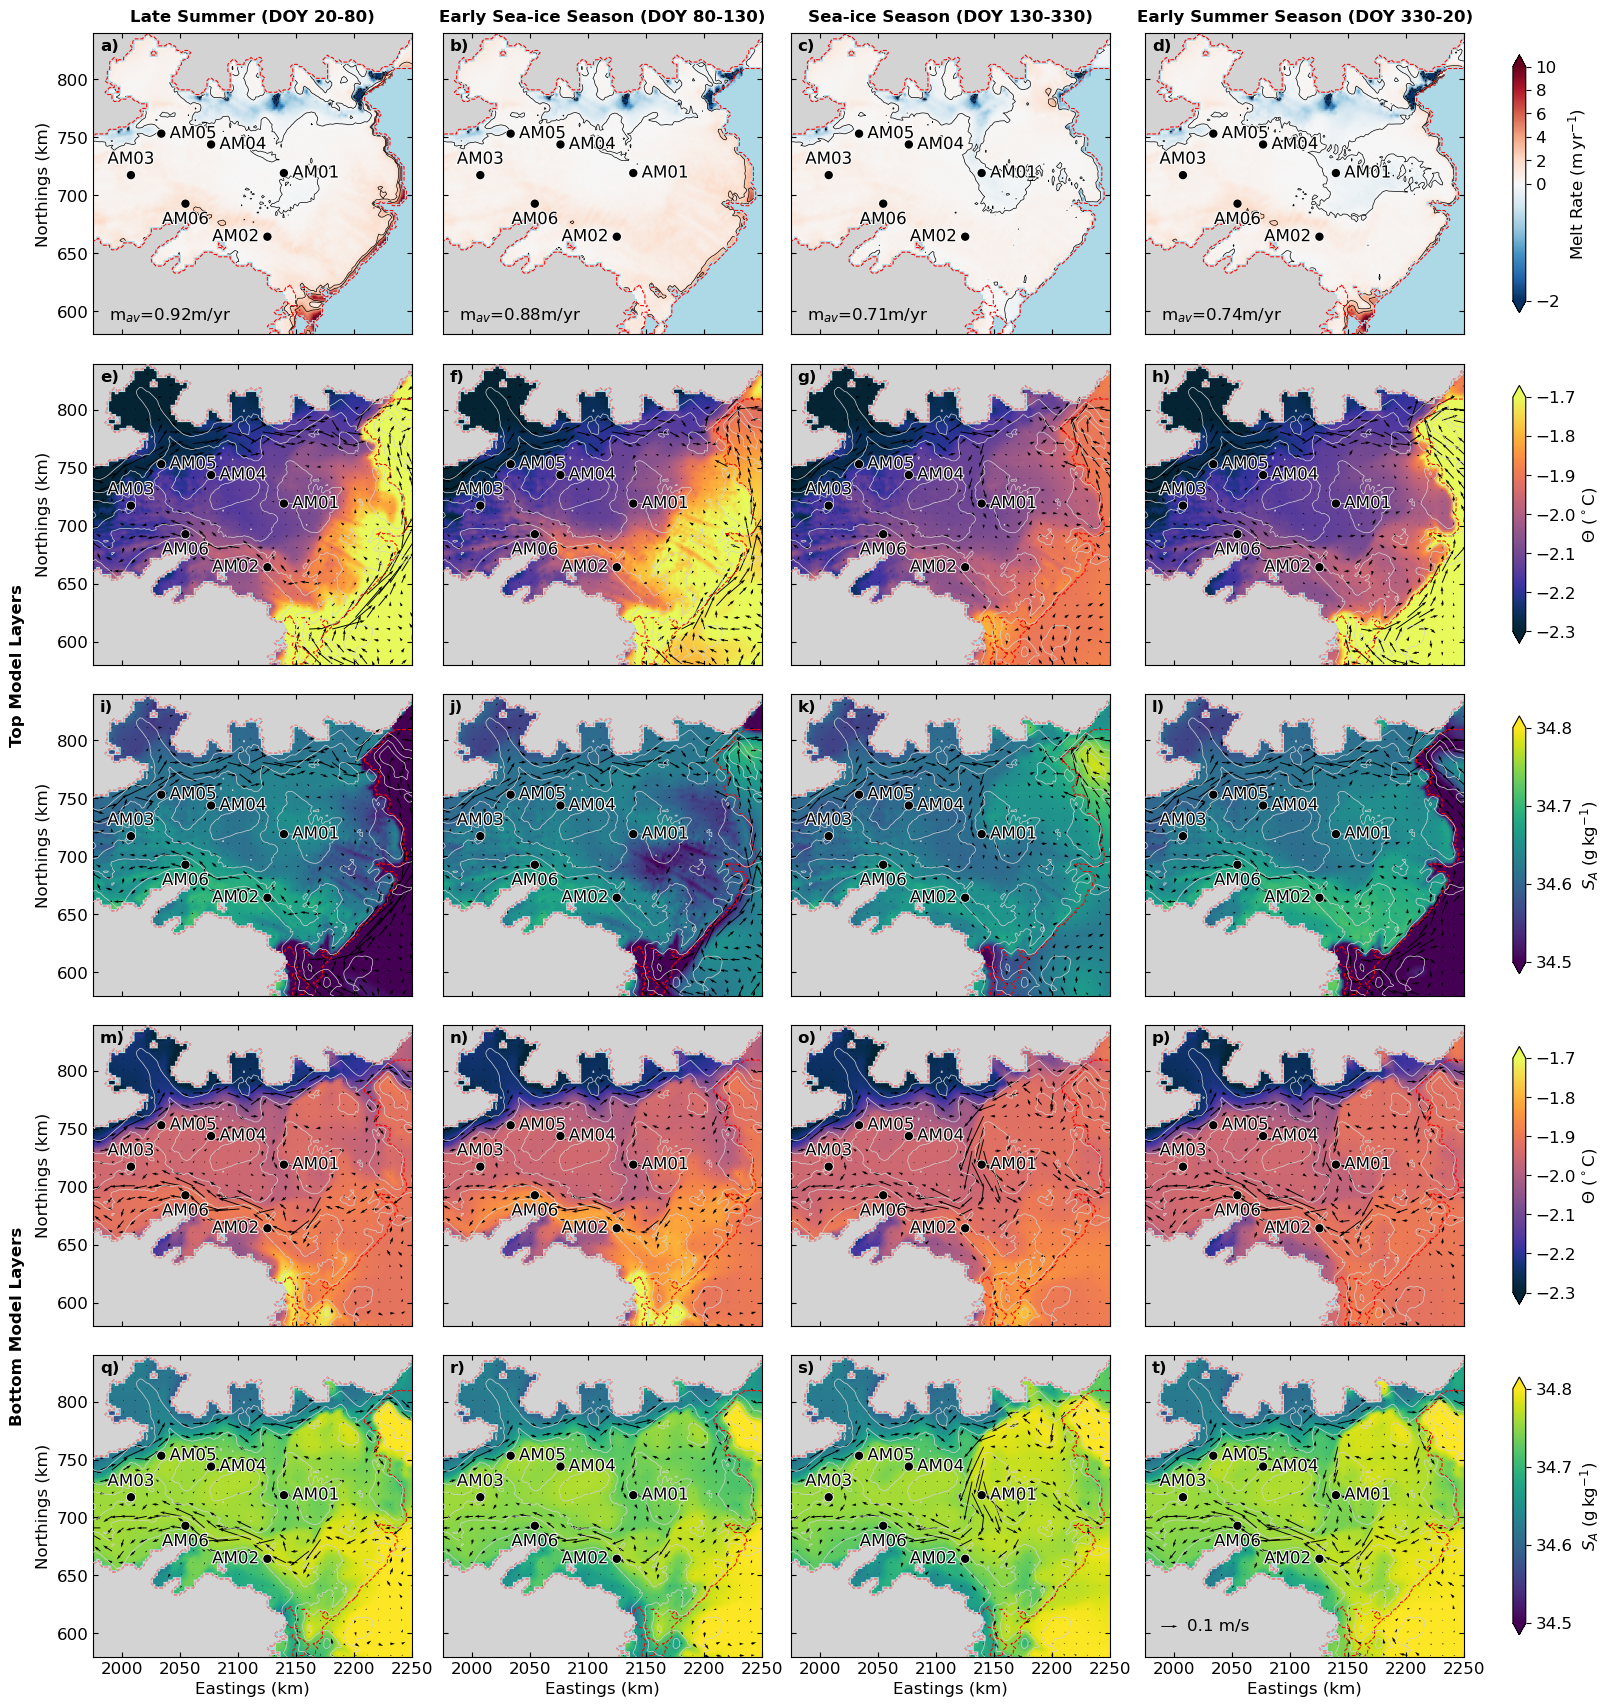

In [28]:
plt.cla()
plt.clf()

# ---------- OCEAN CONDITIONS: BOTTOM MODEL LAYERS ----------
# Vertical layers to average over - s_rho index 0 is the bed
choose_depth = [0, 1, 2, 3, 4]
# Compute the layer thicknesses for the chosen levels
dz_bot = ds_CTRL.dz.isel(s_rho=choose_depth)
# Calculate the total thickness of all chosen levels
dz_sum = dz_bot.sum('s_rho')
# Compute the temperature, salinity and velocity fields across the chosen levels weighted by layer thickness
temp_bot = (ds_CTRL.temp_doy.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum
salt_bot = (ds_CTRL.salt_doy.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum
us_bot_s1 = (us_rho_s1.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum
vs_bot_s1 = (vs_rho_s1.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum
us_bot_s2 = (us_rho_s2.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum
vs_bot_s2 = (vs_rho_s2.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum
us_bot_s3 = (us_rho_s3.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum
vs_bot_s3 = (vs_rho_s3.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum
us_bot_s4 = (us_rho_s4.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum
vs_bot_s4 = (vs_rho_s4.isel(s_rho=choose_depth) * dz_bot).sum('s_rho') / dz_sum

# ---------- OCEAN CONDITIONS: TOP MODEL LAYERS ----------
# Define a list of vertical layers in the model to average across
choose_depth = [-3, -2, -1]
# Compute the layer thicknesses for the chosen levels
dz_top = ds_CTRL.dz.isel(s_rho=choose_depth)
# Calculate the total thickness of all chosen levels
dz_sum = dz_top.sum('s_rho')
# Compute the temperature, salinity and velocity fields across the chosen levels weighted by layer thickness
temp_top = (ds_CTRL.temp_doy.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum
salt_top = (ds_CTRL.salt_doy.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum
us_top_s1 = (us_rho_s1.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum
vs_top_s1 = (vs_rho_s1.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum
us_top_s2 = (us_rho_s2.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum
vs_top_s2 = (vs_rho_s2.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum
us_top_s3 = (us_rho_s3.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum
vs_top_s3 = (vs_rho_s3.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum
us_top_s4 = (us_rho_s4.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum
vs_top_s4 = (vs_rho_s4.isel(s_rho=choose_depth) * dz_top).sum('s_rho') / dz_sum

fig, ax = plt.subplots(nrows=5, ncols=4, figsize=(16,17), layout='constrained')

land = np.where(ds_CTRL.mask_rho.values == 0, 1.0, np.nan)
land_cmap = mcolors.ListedColormap(['lightgrey'])

for i in range(5):
    for j in range(4):
        ax[i,j].set_facecolor('lightblue')
        ax[i,j].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, land, cmap=land_cmap, shading='auto', zorder=0.5)

# Area weights for the region-averaged melt rate annotation
weights_area = (1/ds_CTRL.pm)*(1/ds_CTRL.pn)
weights_area.name = "weights"

# ---------- ROW 0: MELT RATE ----------
ax16=ax[0,0].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, (ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.my_doy.sel(dayofyear=s1)).mean(dim='dayofyear'), **melt_kwargs)
ax[0,0].contour(ds_CTRL.x_rho, ds_CTRL.y_rho, (ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.my_doy.sel(dayofyear=s1)).mean(dim='dayofyear'), colors='k', linewidths=0.5, levels=np.arange(-4,6,2))
m_av0=(ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.mask_zice_roi.where(ds_CTRL.mask_zice_roi,np.nan)*ds_CTRL.my_doy.sel(dayofyear=s1)).mean(dim='dayofyear').weighted(weights_area).mean(('xi_rho','eta_rho')).values.round(2)
ax[0,0].text(.05,.05,(r'm$_{av}$='+str(m_av0)+'m/yr'), transform=ax[0,0].transAxes, zorder=9)

ax17=ax[0,1].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, (ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.my_doy.sel(dayofyear=s2)).mean(dim='dayofyear'), **melt_kwargs)
ax[0,1].contour(ds_CTRL.x_rho, ds_CTRL.y_rho, (ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.my_doy.sel(dayofyear=s2)).mean(dim='dayofyear'), colors='k', linewidths=0.5, levels=np.arange(-4,6,2))
m_av1=(ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.mask_zice_roi.where(ds_CTRL.mask_zice_roi,np.nan)*ds_CTRL.my_doy.sel(dayofyear=s2)).mean(dim='dayofyear').weighted(weights_area).mean(('xi_rho','eta_rho')).values.round(2)
ax[0,1].text(.05,.05,(r'm$_{av}$='+str(m_av1)+'m/yr'), transform=ax[0,1].transAxes, zorder=9)

ax18=ax[0,2].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, (ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.my_doy.sel(dayofyear=s3)).mean(dim='dayofyear'), **melt_kwargs)
ax[0,2].contour(ds_CTRL.x_rho, ds_CTRL.y_rho, (ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.my_doy.sel(dayofyear=s3)).mean(dim='dayofyear'), colors='k', linewidths=0.5, levels=np.arange(-4,6,2))
m_av2=(ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.mask_zice_roi.where(ds_CTRL.mask_zice_roi,np.nan)*ds_CTRL.my_doy.sel(dayofyear=s3)).mean(dim='dayofyear').weighted(weights_area).mean(('xi_rho','eta_rho')).values.round(2)
ax[0,2].text(.05,.05,(r'm$_{av}$='+str(m_av2)+'m/yr'), transform=ax[0,2].transAxes, zorder=9)

ax19=ax[0,3].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, (xr.concat([ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.my_doy.sel(dayofyear=s4_1),ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.my_doy.sel(dayofyear=s4_2)],dim='dayofyear')).mean(dim='dayofyear'), **melt_kwargs)
ax[0,3].contour(ds_CTRL.x_rho, ds_CTRL.y_rho, (xr.concat([ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.my_doy.sel(dayofyear=s4_1),ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.my_doy.sel(dayofyear=s4_2)],dim='dayofyear')).mean(dim='dayofyear'), colors='k', linewidths=0.5, levels=np.arange(-4,6,2))
m_av3=((xr.concat([ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.mask_zice_roi.where(ds_CTRL.mask_zice_roi,np.nan)*ds_CTRL.my_doy.sel(dayofyear=s4_1),ds_CTRL.mask_rho*(ds_CTRL.mask_ziceNaN)*ds_CTRL.mask_zice_roi.where(ds_CTRL.mask_zice_roi,np.nan)*ds_CTRL.my_doy.sel(dayofyear=s4_2)],dim='dayofyear')).mean(dim='dayofyear')).weighted(weights_area).mean(('xi_rho','eta_rho')).values.round(2)
ax[0,3].text(.05,.05,(r'm$_{av}$='+str(m_av3)+'m/yr'), transform=ax[0,3].transAxes, zorder=9)

# ---------- ROW 1: TEMPERATURE (TOP) ----------
ax8=ax[1,0].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_top.sel(dayofyear=s1).mean(dim='dayofyear'), **temp_kwargs)
ax[1,0].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_top_s1.values[0::res,0::res], vs_top_s1.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax9=ax[1,1].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_top.sel(dayofyear=s2).mean(dim='dayofyear'), **temp_kwargs)
ax[1,1].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_top_s2.values[0::res,0::res], vs_top_s2.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax10=ax[1,2].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_top.sel(dayofyear=s3).mean(dim='dayofyear'), **temp_kwargs)
ax[1,2].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_top_s3.values[0::res,0::res], vs_top_s3.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax11=ax[1,3].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, (xr.concat([ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_top.sel(dayofyear=s4_1),ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_top.sel(dayofyear=s4_2)],dim='dayofyear')).mean(dim='dayofyear'), **temp_kwargs)
ax[1,3].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_top_s4.values[0::res,0::res], vs_top_s4.values[0::res,0::res],scale=vel_scale,width=vel_width)

# ---------- ROW 2: SALINITY (TOP) ----------
ax12=ax[2,0].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_top.sel(dayofyear=s1).mean(dim='dayofyear'), **salt_kwargs)
ax[2,0].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_top_s1.values[0::res,0::res], vs_top_s1.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax13=ax[2,1].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_top.sel(dayofyear=s2).mean(dim='dayofyear'), **salt_kwargs)
ax[2,1].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_top_s2.values[0::res,0::res], vs_top_s2.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax14=ax[2,2].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_top.sel(dayofyear=s3).mean(dim='dayofyear'), **salt_kwargs)
ax[2,2].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_top_s3.values[0::res,0::res], vs_top_s3.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax15=ax[2,3].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, (xr.concat([ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_top.sel(dayofyear=s4_1),ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_top.sel(dayofyear=s4_2)],dim='dayofyear')).mean(dim='dayofyear'), **salt_kwargs)
qu = ax[2,3].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_top_s4.values[0::res,0::res], vs_top_s4.values[0::res,0::res],scale=vel_scale,width=vel_width)

# ---------- ROW 5: TEMPERATURE (BOTTOM) ---------- 
ax0=ax[3,0].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_bot.sel(dayofyear=s1).mean(dim='dayofyear'), **temp_kwargs)
ax[3,0].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_bot_s1.values[0::res,0::res], vs_bot_s1.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax1=ax[3,1].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_bot.sel(dayofyear=s2).mean(dim='dayofyear'), **temp_kwargs)
ax[3,1].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_bot_s2.values[0::res,0::res], vs_bot_s2.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax2=ax[3,2].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_bot.sel(dayofyear=s3).mean(dim='dayofyear'), **temp_kwargs)
ax[3,2].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_bot_s3.values[0::res,0::res], vs_bot_s3.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax3=ax[3,3].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, (xr.concat([ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_bot.sel(dayofyear=s4_1),ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_bot.sel(dayofyear=s4_2)],dim='dayofyear')).mean(dim='dayofyear'), **temp_kwargs)
ax[3,3].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_bot_s4.values[0::res,0::res], vs_bot_s4.values[0::res,0::res],scale=vel_scale,width=vel_width)

# ---------- ROW 6: SALINITY (BOTTOM) ----------
ax4=ax[4,0].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_bot.sel(dayofyear=s1).mean(dim='dayofyear'), **salt_kwargs)
ax[4,0].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_bot_s1.values[0::res,0::res], vs_bot_s1.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax5=ax[4,1].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_bot.sel(dayofyear=s2).mean(dim='dayofyear'), **salt_kwargs)
ax[4,1].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_bot_s2.values[0::res,0::res], vs_bot_s2.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax6=ax[4,2].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_bot.sel(dayofyear=s3).mean(dim='dayofyear'), **salt_kwargs)
ax[4,2].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_bot_s3.values[0::res,0::res], vs_bot_s3.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax7=ax[4,3].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, (xr.concat([ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_bot.sel(dayofyear=s4_1),ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_bot.sel(dayofyear=s4_2)],dim='dayofyear')).mean(dim='dayofyear'), **salt_kwargs)
qu = ax[4,3].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], us_bot_s4.values[0::res,0::res], vs_bot_s4.values[0::res,0::res],scale=vel_scale,width=vel_width)

scale_ticks = 1e3
ticks_x = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))
ticks_y = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))

for i in range(5):
    for j in range(4):
        ax[i,j].set_title('')
        ax[i,j].set_ylabel('')
        ax[i,j].set_xlabel('')
        ax[4,j].set_xlabel('Eastings (km)')
        ax[i,j].tick_params(axis="both", direction="in", top=True, right=True)
        if j != 0:
            ax[i,j].tick_params(labelleft=False)
        if i != 4:
            ax[i,j].tick_params(labelbottom=False)
    ax[i,0].set_ylabel('Northings (km)')

for j in range(4):
    style_map(ds_CTRL, ax[0,j], boreholes_amisor, wct_colour=None)
    style_map(ds_CTRL, ax[1,j], boreholes_amisor, wct_colour='lightgrey')
    style_map(ds_CTRL, ax[2,j], boreholes_amisor, wct_colour='lightgrey')
    style_map(ds_CTRL, ax[3,j], boreholes_amisor, wct_colour='lightgrey')
    style_map(ds_CTRL, ax[4,j], boreholes_amisor, wct_colour='lightgrey')

for i in range(5):
    for j in range(4):
        k = i * 4 + j
        panel_letter = chr(97 + k) if k < 26 else 'a' + chr(97 + k - 26)
        ax[i,j].text(0.02, 0.98, f'{chr(97 + k)})', transform=ax[i,j].transAxes, ha='left', va='top', fontweight='bold', zorder=10)
        
season_names = ['Late Summer (DOY 20-80)', 'Early Sea-ice Season (DOY 80-130)', 'Sea-ice Season (DOY 130-330)', 'Early Summer Season (DOY 330-20)']
for j in range(4):
    ax[0, j].annotate(season_names[j], xy=(0.5, 1), xycoords='axes fraction', xytext=(0, 6), textcoords='offset points', ha='center', va='bottom', fontweight='bold')

ax[0, 0].annotate('Melt Rate', xy=(0, 0.5), xycoords=ax[0, 0].yaxis.label, xytext=(-8, 0), textcoords='offset points', ha='right', va='center', rotation=90, fontweight='bold', color='none')
for upper_row, name in [(1, 'Top Model Layers'), (3, 'Bottom Model Layers')]:
    ax[upper_row, 0].annotate(name, xy=(0, 0), xycoords=(ax[upper_row, 0].yaxis.label, 'axes fraction'), xytext=(-8, 0), textcoords='offset points', ha='right', va='center', rotation=90, fontweight='bold', in_layout=False)

ax[1,3].quiverkey(qu, 0.1, 0.1, 0.1, '0.1 m/s', coordinates='axes', labelpos='E')
ax[2,3].quiverkey(qu, 0.1, 0.1, 0.1, '0.1 m/s', coordinates='axes', labelpos='E')
ax[3,3].quiverkey(qu, 0.1, 0.1, 0.1, '0.1 m/s', coordinates='axes', labelpos='E')
ax[4,3].quiverkey(qu, 0.1, 0.1, 0.1, '0.1 m/s', coordinates='axes', labelpos='E')

cbar_m = fig.colorbar(ax16, ax=ax[0, :], location='right', shrink=0.8, pad=0.02, extend='both')
cbar_m.set_label(r'Melt Rate ($\mathrm{m\,yr^{-1}}$)')
cbar_m.ax.tick_params(labelsize=12)
cbar_t = fig.colorbar(ax11, ax=ax[1, :], location='right', shrink=0.8, pad=0.02, extend='both')
cbar_t.set_label(r'$\Theta$ ($^\circ$C)')
cbar_t.ax.tick_params(labelsize=12)
cbar_s = fig.colorbar(ax15, ax=ax[2, :], location='right', shrink=0.8, pad=0.02, extend='both')
cbar_s.set_label(r'$S_A$ ($\mathrm{g\,kg^{-1}}$)')
cbar_s.ax.tick_params(labelsize=12)
cbar_s.ax.yaxis.set_major_locator(mticker.MultipleLocator(0.1))
cbar_t = fig.colorbar(ax3, ax=ax[3, :], location='right', shrink=0.8, pad=0.02, extend='both')
cbar_t.set_label(r'$\Theta$ ($^\circ$C)')
cbar_t.ax.tick_params(labelsize=12)
cbar_s = fig.colorbar(ax7, ax=ax[4, :], location='right', shrink=0.8, pad=0.02, extend='both')
cbar_s.set_label(r'$S_A$ ($\mathrm{g\,kg^{-1}}$)')
cbar_s.ax.tick_params(labelsize=12)
cbar_s.ax.yaxis.set_major_locator(mticker.MultipleLocator(0.1))

fig.canvas.draw()
fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ModelFields.jpg', format='jpg', dpi=300)
plt.show()

## Figure SI: Model Temperature-Salinity-Velocity-Melt Rate Fields (Depth-Integrated Layers)

<Figure size 640x480 with 0 Axes>

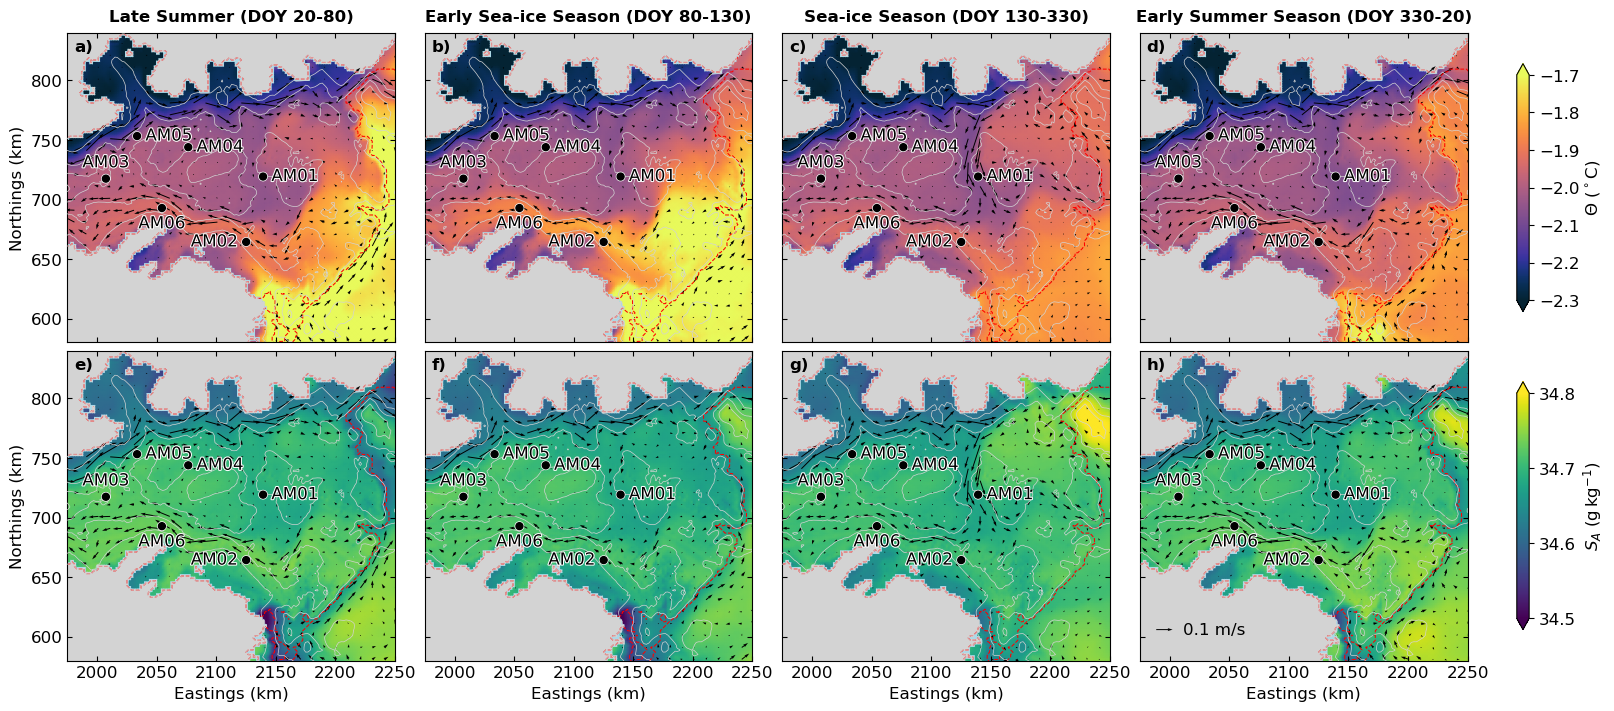

In [29]:
plt.cla()
plt.clf()

# ---------- OCEAN CONDITIONS: FULL WATER COLUMN ----------
dz_all = ds_CTRL.dz
dz_sum = dz_all.sum('s_rho')

temp_s1 = ds_CTRL.temp_doy.sel(dayofyear=s1).mean(dim='dayofyear')
temp_s2 = ds_CTRL.temp_doy.sel(dayofyear=s2).mean(dim='dayofyear')
temp_s3 = ds_CTRL.temp_doy.sel(dayofyear=s3).mean(dim='dayofyear')
temp_s4 = xr.concat([ds_CTRL.temp_doy.sel(dayofyear=s4_1), ds_CTRL.temp_doy.sel(dayofyear=s4_2)], dim='dayofyear').mean(dim='dayofyear')
salt_s1 = ds_CTRL.salt_doy.sel(dayofyear=s1).mean(dim='dayofyear')
salt_s2 = ds_CTRL.salt_doy.sel(dayofyear=s2).mean(dim='dayofyear')
salt_s3 = ds_CTRL.salt_doy.sel(dayofyear=s3).mean(dim='dayofyear')
salt_s4 = xr.concat([ds_CTRL.salt_doy.sel(dayofyear=s4_1), ds_CTRL.salt_doy.sel(dayofyear=s4_2)], dim='dayofyear').mean(dim='dayofyear')

temp_avg_s1 = (temp_s1 * dz_all).sum('s_rho') / dz_sum
temp_avg_s2 = (temp_s2 * dz_all).sum('s_rho') / dz_sum
temp_avg_s3 = (temp_s3 * dz_all).sum('s_rho') / dz_sum
temp_avg_s4 = (temp_s4 * dz_all).sum('s_rho') / dz_sum
salt_avg_s1 = (salt_s1 * dz_all).sum('s_rho') / dz_sum
salt_avg_s2 = (salt_s2 * dz_all).sum('s_rho') / dz_sum
salt_avg_s3 = (salt_s3 * dz_all).sum('s_rho') / dz_sum
salt_avg_s4 = (salt_s4 * dz_all).sum('s_rho') / dz_sum

fig, ax = plt.subplots(nrows=2, ncols=4, figsize=(16, 7), layout='constrained')

land = np.where(ds_CTRL.mask_rho.values == 0, 1.0, np.nan)
land_cmap = mcolors.ListedColormap(['lightgrey'])

for i in range(2):
    for j in range(4):
        ax[i,j].set_facecolor('lightblue')
        ax[i,j].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, land, cmap=land_cmap, shading='auto', zorder=0.5)

# ---------- ROW 0: TEMPERATURE (DEPTH-AVERAGED) ----------
ax0=ax[0,0].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_avg_s1, **temp_kwargs)
ax[0,0].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], ubar_rho_s1.values[0::res,0::res], vbar_rho_s1.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax1=ax[0,1].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_avg_s2, **temp_kwargs)
ax[0,1].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], ubar_rho_s2.values[0::res,0::res], vbar_rho_s2.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax2=ax[0,2].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_avg_s3, **temp_kwargs)
ax[0,2].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], ubar_rho_s3.values[0::res,0::res], vbar_rho_s3.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax3=ax[0,3].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*temp_avg_s4, **temp_kwargs)
qu = ax[0,3].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], ubar_rho_s4.values[0::res,0::res], vbar_rho_s4.values[0::res,0::res],scale=vel_scale,width=vel_width)

# ---------- ROW 1: SALINITY (DEPTH-AVERAGED) ----------
ax4=ax[1,0].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_avg_s1, **salt_kwargs)
ax[1,0].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], ubar_rho_s1.values[0::res,0::res], vbar_rho_s1.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax5=ax[1,1].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_avg_s2, **salt_kwargs)
ax[1,1].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], ubar_rho_s2.values[0::res,0::res], vbar_rho_s2.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax6=ax[1,2].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_avg_s3, **salt_kwargs)
ax[1,2].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], ubar_rho_s3.values[0::res,0::res], vbar_rho_s3.values[0::res,0::res],scale=vel_scale,width=vel_width)
ax7=ax[1,3].pcolormesh(ds_CTRL.x_rho, ds_CTRL.y_rho, ds_CTRL.mask_rho*(ds_CTRL.mask_rhoNaN)*salt_avg_s4, **salt_kwargs)
qu = ax[1,3].quiver(grd.x_rho.values[0::res,0::res], grd.y_rho.values[0::res,0::res], ubar_rho_s4.values[0::res,0::res], vbar_rho_s4.values[0::res,0::res],scale=vel_scale,width=vel_width)

scale_ticks = 1e3
ticks_x = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))
ticks_y = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))

for i in range(2):
    for j in range(4):
        ax[i,j].set_title('')
        ax[i,j].set_ylabel('')
        ax[i,j].set_xlabel('')
        ax[1,j].set_xlabel('Eastings (km)')
        ax[i,j].tick_params(axis="both", direction="in", top=True, right=True)
        if j != 0:
            ax[i,j].tick_params(labelleft=False)
        if i != 1:
            ax[i,j].tick_params(labelbottom=False)
    ax[i,0].set_ylabel('Northings (km)')

for j in range(4):
    style_map(ds_CTRL, ax[0,j], boreholes_amisor, wct_colour='lightgrey')
    style_map(ds_CTRL, ax[1,j], boreholes_amisor, wct_colour='lightgrey')

# Panel letters inside the top-left corner of each panel, lettered left-to-right then down
for i in range(2):
    for j in range(4):
        k = i * 4 + j
        ax[i,j].text(0.02, 0.98, f'{chr(97 + k)})', transform=ax[i,j].transAxes, ha='left', va='top', fontweight='bold', zorder=10)

season_names = ['Late Summer (DOY 20-80)', 'Early Sea-ice Season (DOY 80-130)', 'Sea-ice Season (DOY 130-330)', 'Early Summer Season (DOY 330-20)']
for j in range(4):
    ax[0, j].annotate(season_names[j], xy=(0.5, 1), xycoords='axes fraction', xytext=(0, 6), textcoords='offset points', ha='center', va='bottom', fontweight='bold')

ax[0,3].quiverkey(qu, 0.1, 0.1, 0.1, '0.1 m/s', coordinates='axes', labelpos='E')
ax[1,3].quiverkey(qu, 0.1, 0.1, 0.1, '0.1 m/s', coordinates='axes', labelpos='E')

cbar_t = fig.colorbar(ax3, ax=ax[0, :], location='right', shrink=0.8, pad=0.02, extend='both')
cbar_t.set_label(r'$\Theta$ ($^\circ$C)')
cbar_t.ax.tick_params(labelsize=12)
cbar_s = fig.colorbar(ax7, ax=ax[1, :], location='right', shrink=0.8, pad=0.02, extend='both')
cbar_s.set_label(r'$S_A$ ($\mathrm{g\,kg^{-1}}$)')
cbar_s.ax.tick_params(labelsize=12)
cbar_s.ax.yaxis.set_major_locator(mticker.MultipleLocator(0.1))

fig.canvas.draw()
fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/ModelFieldsDepthAveraged.jpg', format='jpg', dpi=300)
plt.show()